<a href="https://colab.research.google.com/github/Sayandt-web/B_80_Set3/blob/main/B_80_Set3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

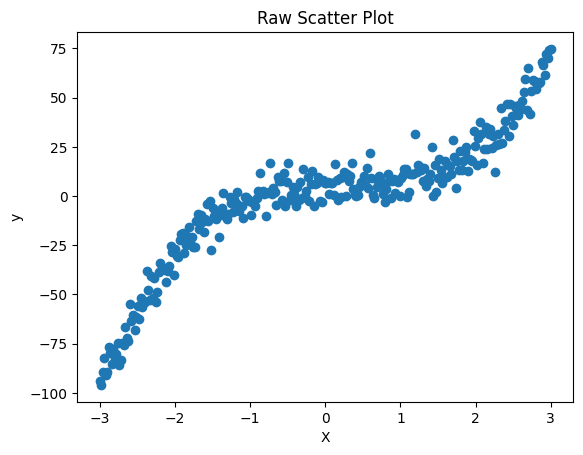

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
n = 300
X = np.linspace(-3, 3, n)

noise = np.random.normal(0, 6, n)

y = 3*X**3 - 2*X**2 + X + 5 + noise

X = X.reshape(-1,1)

plt.scatter(X, y)
plt.title("Raw Scatter Plot")
plt.xlabel("X")
plt.ylabel("y")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.6, random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_train_pred_linear = linear_model.predict(X_train)
y_test_pred_linear = linear_model.predict(X_test)

In [ ]:
poly4 = Pipeline([
    ("poly", PolynomialFeatures(degree=4)),
    ("model", LinearRegression())
])

poly4.fit(X_train, y_train)

y_train_pred_poly4 = poly4.predict(X_train)
y_test_pred_poly4 = poly4.predict(X_test)


In [ ]:
poly12 = Pipeline([
    ("poly", PolynomialFeatures(degree=12)),
    ("model", LinearRegression())
])

poly12.fit(X_train, y_train)

y_train_pred_poly12 = poly12.predict(X_train)
y_test_pred_poly12 = poly12.predict(X_test)

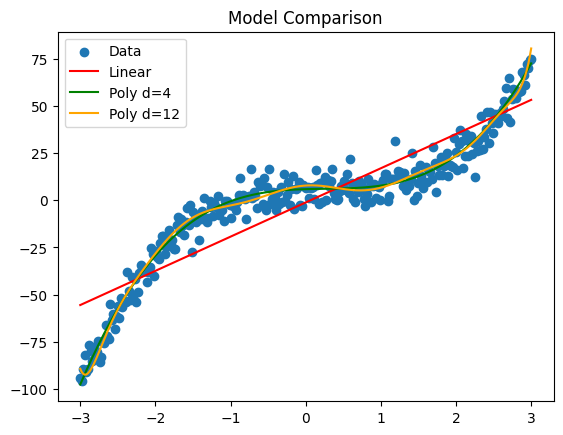

In [ ]:
plt.scatter(X, y, label="Data")

X_sorted = np.sort(X, axis=0)

plt.plot(X_sorted, linear_model.predict(X_sorted), label="Linear", color="red")
plt.plot(X_sorted, poly4.predict(X_sorted), label="Poly d=4", color="green")
plt.plot(X_sorted, poly12.predict(X_sorted), label="Poly d=12", color="orange")

plt.legend()
plt.title("Model Comparison")
plt.show()

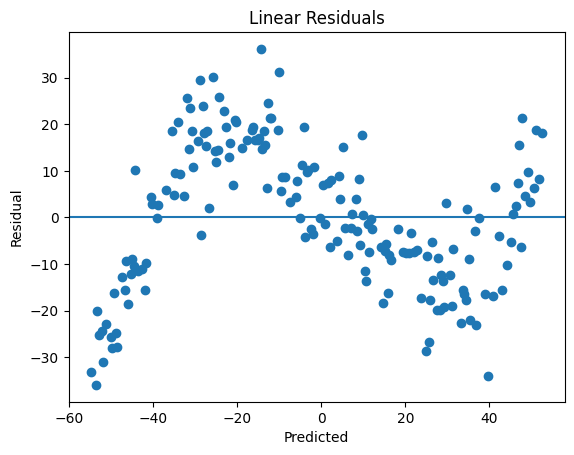

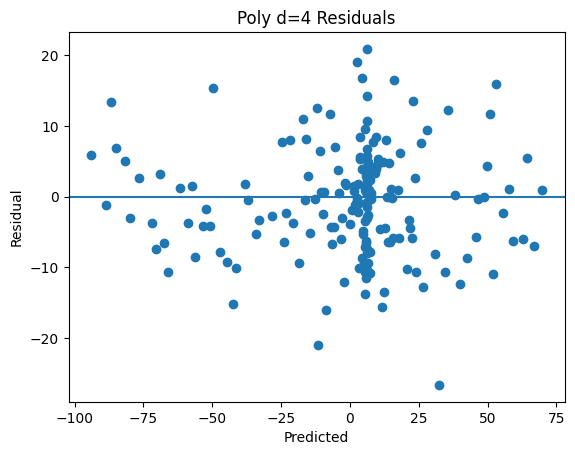

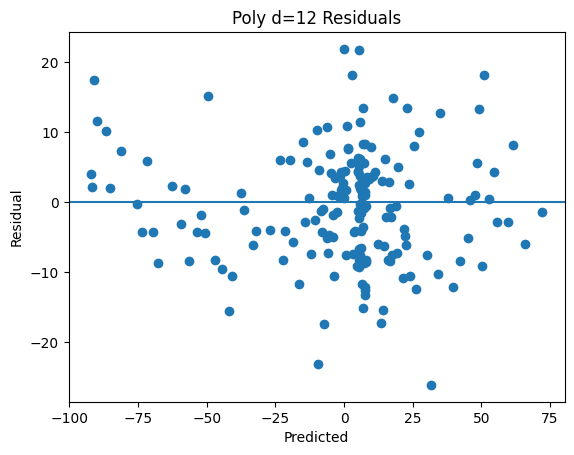

In [ ]:
def residual_plot(y_true, y_pred, title):
    residuals = y_true - y_pred
    plt.scatter(y_pred, residuals)
    plt.axhline(0)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Residual")
    plt.show()

residual_plot(y_test, y_test_pred_linear, "Linear Residuals")
residual_plot(y_test, y_test_pred_poly4, "Poly d=4 Residuals")
residual_plot(y_test, y_test_pred_poly12, "Poly d=12 Residuals")

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

def metrics(y_train, y_train_pred, y_test, y_test_pred, name):

    print("\n", name)

    print("Train R2:", r2_score(y_train, y_train_pred))
    print("Test R2:", r2_score(y_test, y_test_pred))

    print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
    print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

    print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
    print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

metrics(y_train, y_train_pred_linear, y_test, y_test_pred_linear, "Linear")
metrics(y_train, y_train_pred_poly4, y_test, y_test_pred_poly4, "Poly d=4")
metrics(y_train, y_train_pred_poly12, y_test, y_test_pred_poly12, "Poly d=12")


 Linear
Train R2: 0.8039394959352436
Test R2: 0.7810355333798262
Train RMSE: 16.217207959409972
Test RMSE: 15.296620942190561
Train MAE: 13.31916825296815
Test MAE: 12.790240217109725

 Poly d=4
Train R2: 0.9524388136036177
Test R2: 0.9438280616969403
Train RMSE: 7.987435572908084
Test RMSE: 7.747621364462116
Train MAE: 6.288554626720892
Test MAE: 6.084799848458126

 Poly d=12
Train R2: 0.9554936338767448
Test R2: 0.9388847562918363
Train RMSE: 7.726665237226707
Test RMSE: 8.081341452699156
Train MAE: 5.956661824037626
Test MAE: 6.382349037102229


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X = X.reshape(-1,1)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
def train_and_evaluate(X_train, X_test, y_train, y_test):

    poly = PolynomialFeatures(degree=4)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)

    return train_rmse, test_rmse, train_mae, test_mae

In [ ]:
X_train_A, X_test_A, y_train_A, y_test_A = train_test_split(
    X, y, test_size=0.3, random_state=42)

results_A = train_and_evaluate(X_train_A, X_test_A, y_train_A, y_test_A)

print("Split A Results:")
print("Train RMSE:", results_A[0])
print("Test RMSE:", results_A[1])
print("Train MAE:", results_A[2])
print("Test MAE:", results_A[3])

Split A Results:
Train RMSE: 6.178982021327463
Test RMSE: 5.058674503470144
Train MAE: 4.912093544589048
Test MAE: 3.95982781157037


In [ ]:
X_train_B, X_test_B, y_train_B, y_test_B = train_test_split(
    X, y, test_si3ze=0.3, random_state=7)

results_B = train_and_evaluate(X_train_B, X_test_B, y_train_B, y_test_B)

print("\nSplit B Results:")
print("Train RMSE:", results_B[0])
print("Test RMSE:", results_B[1])
print("Train MAE:", results_B[2])
print("Test MAE:", results_B[3])


Split B Results:
Train RMSE: 5.735551582342756
Test RMSE: 6.150963602068439
Train MAE: 4.595310131838343
Test MAE: 4.6572737567236935


In [ ]:
sorted_index = np.argsort(X.flatten())

X_sorted = X[sorted_index]
y_sorted = y[sorted_index]

split_point = int(0.7 * len(X))

X_train_C = X_sorted[:split_point]
X_test_C = X_sorted[split_point:]

y_train_C = y_sorted[:split_point]
y_test_C = y_sorted[split_point:]

results_C = train_and_evaluate(X_train_C, X_test_C, y_train_C, y_test_C)

print("\nSplit C Results:")
print("Train RMSE:", results_C[0])
print("Test RMSE:", results_C[1])
print("Train MAE:", results_C[2])
print("Test MAE:", results_C[3])


Split C Results:
Train RMSE: 5.688077854218767
Test RMSE: 36.61193776892414
Train MAE: 4.44365392502289
Test MAE: 29.4598942021033


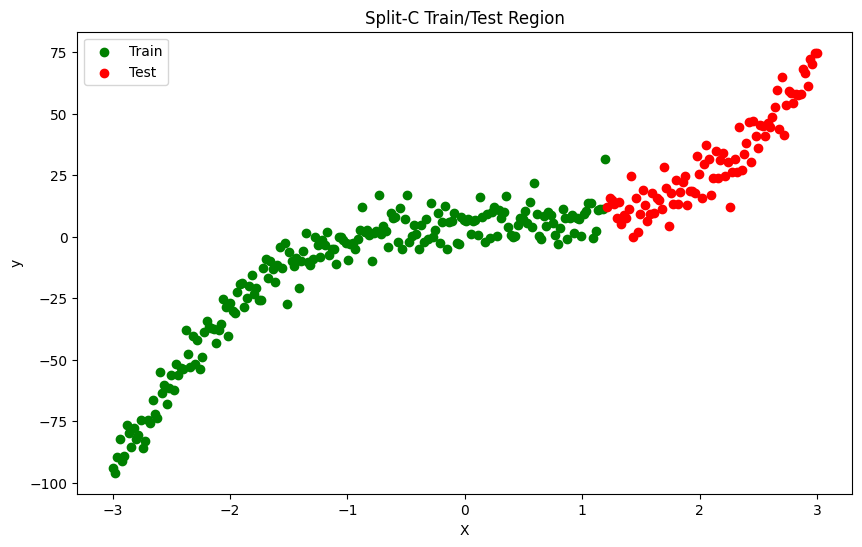

In [ ]:
plt.figure(figsize=(10,6))

plt.scatter(X_train_C, y_train_C, color='green', label='Train')
plt.scatter(X_test_C, y_test_C, color='red', label='Test')

plt.xlabel("X")
plt.ylabel("y")
plt.title("Split-C Train/Test Region")
plt.legend()

plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("poly", PolynomialFeatures(degree=4)),
    ("model", LinearRegression())
])

rmse_scores = np.sqrt(-cross_val_score(
    pipeline, X, y,
    scoring="neg_mean_squared_error",
    cv=5))

print("RMSE Scores:", rmse_scores)

print("Mean RMSE:", rmse_scores.mean())
print("Standard Deviation:", rmse_scores.std())

RMSE Scores: [10.73804671  5.68275537  5.95077894  6.18901073  6.213938  ]
Mean RMSE: 6.9549059517092315
Standard Deviation: 1.9012848901336834
